In [1]:
from pathlib import Path

import pandas as pd

DATASET_PATH = Path("data/raw/telco_customer_churn.csv")

df = pd.read_csv(DATASET_PATH)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df["TotalCharges"].head(10)

0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str

In [5]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

In [6]:
invalid_total_charges = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce",
).isna()

df.loc[
    invalid_total_charges,
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"],
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [7]:
df.loc[
    df["tenure"] == 0,
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"],
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [8]:
(df["tenure"] == 0).sum()

np.int64(11)

## Análise da variável-alvo (Churn)

Nesta etapa, analisamos a distribuição dos clientes que cancelaram
e dos que permaneceram na empresa.

In [9]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

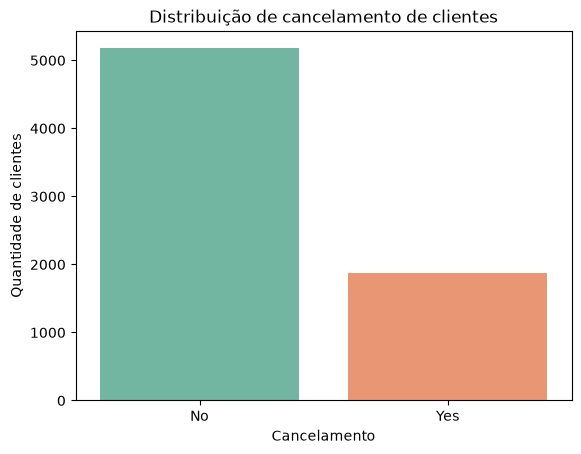

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False,
)

plt.title("Distribuição de cancelamento de clientes")
plt.xlabel("Cancelamento")
plt.ylabel("Quantidade de clientes")
plt.show()

## Relação entre tipo de contrato e cancelamento

Análise da distribuição de Churn para cada modalidade de contrato.

In [12]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
)

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [13]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index",
) * 100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [14]:
df.groupby("Contract")["tenure"].median()

Contract
Month-to-month    12.0
One year          44.0
Two year          64.0
Name: tenure, dtype: float64

In [15]:
df.groupby("Churn")["tenure"].median()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

In [16]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


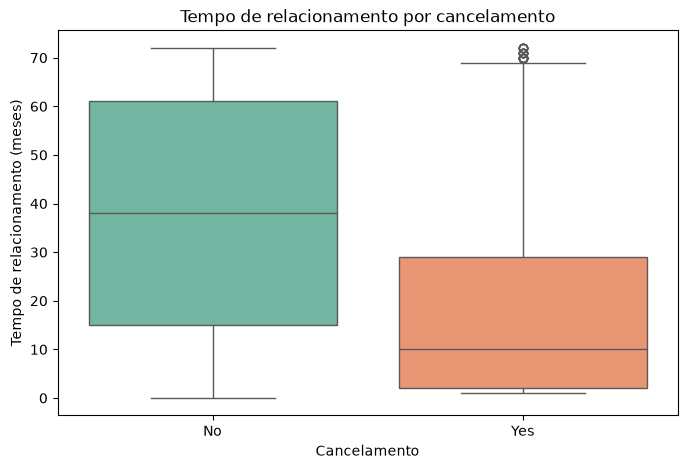

In [17]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette="Set2",
    legend=False,
)

plt.title("Tempo de relacionamento por cancelamento")
plt.xlabel("Cancelamento")
plt.ylabel("Tempo de relacionamento (meses)")
plt.show()

In [18]:
tenure_ranges = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 meses", "13-24 meses", "25-48 meses", "49-72 meses"],
)

churn_by_contract_tenure = (
    pd.crosstab(
        [df["Contract"], tenure_ranges],
        df["Churn"],
        normalize="index",
    )
    * 100
)

churn_by_contract_tenure.round(2)

Churn                           No    Yes
Contract       tenure                    
Month-to-month 0-12 meses    48.65  51.35
               13-24 meses   62.28  37.72
               25-48 meses   67.08  32.92
               49-72 meses   73.98  26.02
One year       0-12 meses    89.52  10.48
               13-24 meses   91.88   8.12
               25-48 meses   89.38  10.62
               49-72 meses   87.07  12.93
Two year       0-12 meses   100.00   0.00
               13-24 meses  100.00   0.00
               25-48 meses   97.81   2.19
               49-72 meses   96.67   3.33

In [19]:
pd.crosstab(
    [df["Contract"], tenure_ranges],
    df["Churn"],
    margins=True,
)

Churn                         No   Yes   All
Contract       tenure                       
Month-to-month 0-12 meses    970  1024  1994
               13-24 meses   459   278   737
               25-48 meses   538   264   802
               49-72 meses   253    89   342
One year       0-12 meses    111    13   124
               13-24 meses   181    16   197
               25-48 meses   463    55   518
               49-72 meses   552    82   634
Two year       0-12 meses     68     0    68
               13-24 meses    90     0    90
               25-48 meses   268     6   274
               49-72 meses  1221    42  1263
All                         5174  1869  7043

In [20]:
df.groupby("Churn")["MonthlyCharges"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


In [21]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
)

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


In [22]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index",
).mul(100).round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [23]:
df.groupby("InternetService")["MonthlyCharges"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
InternetService,,,,,,,,
DSL,2421.0,58.10,16.26,23.45,46.20,56.15,69.90,94.80
Fiber optic,3096.0,91.50,12.66,67.75,80.55,91.68,101.15,118.75
No,1526.0,21.08,2.16,18.25,19.70,20.15,20.90,26.90


In [24]:
df.groupby("InternetService")["MonthlyCharges"].median().round(2)

InternetService
DSL            56.15
Fiber optic    91.68
No             20.15
Name: MonthlyCharges, dtype: float64

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df["customerID"].duplicated().sum()

np.int64(0)